# Week 3 Assignment: Linear Regression & Logistic Regression
**AI and Machine Learning Track**
## Instructions
1. Work through the notebook **from top to bottom**. Run every cell in order.
2. Replace each `# YOUR CODE HERE` cell with your own code. Read the **hint** under it if you get stuck.
3. For the **written answers**, double-click the answer box and type 2 to 4 sentences **in your own words**.
4. Before submitting, click **Kernel > Restart & Run All** (or *Runtime > Restart and run all* in Colab) to confirm your whole notebook runs without errors.
5. Save the notebook with the name `Week3_Assignment_YourName.ipynb` and submit it.


In [1]:
# Run this cell first. You may add more imports if you need them.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_score, recall_score)

---
# PART A: Linear Regression 
## Scenario
A shop in Abuja sells **used laptops**. The owner wants a model that suggests a fair selling price from the laptop's **RAM**, **storage** and **age**. You have records of **250 past sales**.

| Column | Meaning |
|---|---|
| `ram_gb` | RAM in gigabytes |
| `storage_gb` | Storage in gigabytes |
| `age_years` | Age of the laptop in years |
| `price_thousand` | Selling price in thousands of naira (**the label we want to predict**) |

In [2]:
# Run this cell to create the dataset. Do not change it.
rng = np.random.default_rng(2024)
n = 250

laptops = pd.DataFrame({
    "ram_gb":     rng.choice([4, 8, 16, 32], n, p=[0.2, 0.4, 0.3, 0.1]),
    "storage_gb": rng.choice([128, 256, 512, 1024], n, p=[0.2, 0.35, 0.3, 0.15]),
    "age_years":  rng.integers(0, 7, n),
})
laptops["price_thousand"] = (
    150 + 9 * laptops["ram_gb"] + 0.12 * laptops["storage_gb"]
    - 18 * laptops["age_years"] + rng.normal(0, 25, n)
).round(1)

laptops.head()

,ram_gb,storage_gb,age_years,price_thousand
0,16,1024,6,331.0
1,8,128,2,201.4
2,8,128,1,194.8
3,16,256,6,253.0
4,32,512,1,515.5


### A1. Explore the data

Using code, show: (a) the number of rows and columns, (b) the summary statistics, (c) whether there are missing values, and (d) the **correlation of every column with `price_thousand`**.

Then draw **one scatter plot** of `age_years` against `price_thousand` with axis labels and a title.

In [3]:
# (a) Number of rows and columns
print("Number of rows and columns:", laptops.shape)

# (b) Summary statistics 
print("\nSummary statistics:")
print(laptops.describe())

# (c) Check for missing values
print("\nMissing values in each column:")
print(laptops.isnull().sum())

# (d) Correlation 0f every column with price_thousand
print("\nCorrelation with price_thousand:")
print(laptops.corr(numeric_only=True)["price_thousand"])

# Hint: `.shape`, `.describe()`, `.isnull().sum()`, `.corr()`, `plt.scatter(...)`.

Number of rows and columns: (250, 4)

Summary statistics:
           ram_gb   storage_gb   age_years  price_thousand
count  250.000000   250.000000  250.000000      250.000000
mean    11.296000   420.864000    3.220000      243.942400
std      7.739767   294.182451    1.986804       90.765017
min      4.000000   128.000000    0.000000       54.800000
25%      8.000000   256.000000    1.000000      177.650000
50%      8.000000   256.000000    3.000000      231.100000
75%     16.000000   512.000000    5.000000      284.900000
max     32.000000  1024.000000    6.000000      515.500000

Missing values in each column:
ram_gb            0
storage_gb        0
age_years         0
price_thousand    0
dtype: int64

Correlation with price_thousand:
ram_gb            0.808453
storage_gb        0.404458
age_years        -0.355518
price_thousand    1.000000
Name: price_thousand, dtype: float64


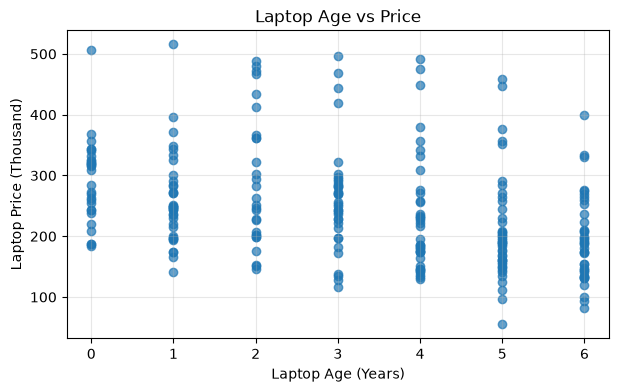

In [4]:
#Scatter plot of age_years against price_thousand 
plt.figure(figsize=(7, 4))
plt.scatter(laptops["age_years"], laptops["price_thousand"], alpha=0.7)
plt.xlabel("Laptop Age (Years)")
plt.ylabel("Laptop Price (Thousand)")
plt.title("Laptop Age vs Price")
plt.grid(alpha=0.3)
plt.show()

### A2. Prepare the data  
Create `X` (the three feature columns) and `y` (the label). Split into **80% training and 20% testing** using `random_state=42`. Print the number of rows in each set.

In [5]:
# Select the three feature columns
X = laptops[["ram_gb", "storage_gb", "age_years"]]

# Select the target column, contains the laptop price that the model will learn to predict.
y = laptops["price_thousand"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Print the number of rows in each set 
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

# Hint: `laptops[[...]]`, `train_test_split(X, y, test_size=..., random_state=...)`.

Training rows: 200
Testing rows: 50


### A3. Train the model 

Train a **Linear Regression** model on the training data. Print the **intercept** and show the **coefficients in a table** (one row per feature).

In [6]:
# Create the Linear regression model
model = LinearRegression()

#Train the model(learning process/step)
model.fit(X_train, y_train)

#Print the intercept
print("Intercept:", model.intercept_)

#Display coeffiecient in a table
coefficients = pd.DataFrame({"Features": X.columns, "Coefficient": model.coef_})
print(coefficients)
# Hint: `LinearRegression()`, `.fit()`, `.intercept_`, `.coef_`, `pd.DataFrame(...)`.

Intercept: 145.23408255249475
     Features  Coefficient
0      ram_gb     8.824934
1  storage_gb     0.123560
2   age_years   -16.160301


### A4. Interpret the coefficients 

In your own words, explain what the coefficient of `age_years` means for the shop owner. Is it positive or negative, and does that make sense? Then say what the coefficient of `ram_gb` tells you.

The coefficient of age_years is negative(-16.1603), meaning that for every additional year of laptop age, the predicted price decreases by approximately 16.16 thousand units. This makes sense because laptops generally depreciate as they get older. The positive RAM coefficient(8.8249) means each additional 1GB of RAM increases the predicted laptop price by about 8.82 thousand units, assuming other features remain constant. 

*(double-click here and type your answer)*

### A5. Make a prediction 

Use your model to predict the price of a laptop with **16 GB RAM, 512 GB storage and 2 years old**. Print the answer in a sentence, for example: *"The predicted price is about N___ thousand."*

In [7]:
new_laptop = pd.DataFrame({"ram_gb":[16], "storage_gb": [512], "age_years": [2]})

#Predict the laptop's price
predicted_price = model.predict(new_laptop)[0]

print(f"The predicted price of the laptop is about {predicted_price:.2f} thousand units.")
# Hint: Put the new laptop in a DataFrame with the **same column names** as `X`, then use `model.predict(...)`.

The predicted price of the laptop is about 317.37 thousand units.


### A6. Evaluate the model 

Predict on the **test set** and calculate **MAE, RMSE and R²**. Print each with a short label.

Then draw an **Actual vs Predicted** scatter plot with a red dashed line showing perfect prediction.

MAE: 21.28
RMSE: 28.08
R2 Score: 0.929


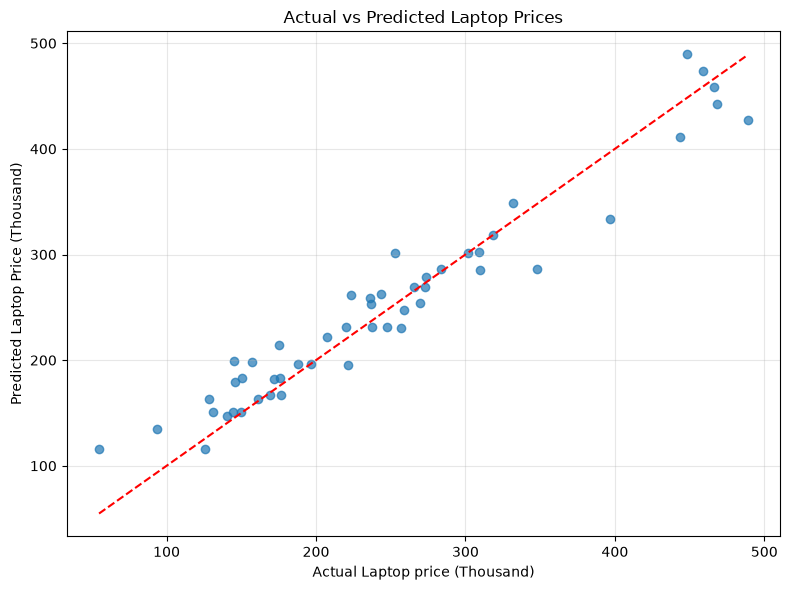

In [8]:
# Predict prices for the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

#Print results
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2)) 
print("R2 Score:", round(r2, 3)) 

#Actual vs Predicted scatter plot
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.7)

#Red dashed line for perfect prediction
plt.plot (
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    label="Perfect Prediction"
    )

plt.xlabel("Actual Laptop price (Thousand)")
plt.ylabel ("Predicted Laptop Price (Thousand)")
plt.title("Actual vs Predicted Laptop Prices")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Hint: `model.predict(X_test)`, `mean_absolute_error`, `mean_squared_error` (then `np.sqrt`), `r2_score`.

### A7. Is the model good?  

Use your MAE and R² values to explain, in plain language, how good the model is. Would you trust it to price laptops in the shop? Give one idea for improving it.

The model's perfomance depends on its MAE and R2 score. A low MAE and an R2 score close to 1 indicate better predictions. I would use the model as a guide for estimating laptop prices, but i wouldd compare its predictions with actual marrket prices before relying on it.

---
# PART B: Logistic Regression 
## Scenario
A microfinance company in Nigeria gives small loans. For each past loan they know whether the customer **repaid (1)** or **did not repay (0)**. They want a model to help decide whether to approve **new** applicants. You have records of **400 past loans**.

| Column | Meaning |
|---|---|
| `monthly_income_k` | Customer's monthly income (N thousand) |
| `loan_amount_k` | Loan amount requested (N thousand) |
| `years_employed` | Years in current job or business |
| `previous_defaults` | Number of earlier loans not repaid |
| `repaid` | 1 = repaid, 0 = did not repay (**the label**) |

In [9]:
# Run this cell to create the dataset. Do not change it.
rng = np.random.default_rng(99)
m = 400

loans = pd.DataFrame({
    "monthly_income_k":  rng.normal(120, 40, m).clip(30).round(0),
    "loan_amount_k":     rng.uniform(20, 500, m).round(0),
    "years_employed":    rng.uniform(0, 15, m).round(1),
    "previous_defaults": np.minimum(rng.poisson(0.6, m), 3),
})
z = (-1.0 + 0.025 * loans["monthly_income_k"] - 0.008 * loans["loan_amount_k"]
     + 0.12 * loans["years_employed"] - 1.2 * loans["previous_defaults"])
prob = 1 / (1 + np.exp(-z))
loans["repaid"] = (rng.random(m) < prob).astype(int)

loans.head()

,monthly_income_k,loan_amount_k,years_employed,previous_defaults,repaid
0,123.0,407.0,14.0,2,1
1,101.0,407.0,2.1,1,0
2,122.0,339.0,12.9,0,1
3,147.0,408.0,8.6,0,1
4,50.0,202.0,2.3,1,0


### B1. Explore the data

Show (a) how many loans were repaid and not repaid (counts **and** percentages), and (b) the **average of each feature for repaid vs not repaid** loans.

Then, in one sentence in a comment or print statement, say which feature seems to differ the most between the two groups.

In [10]:
#(a) Count loans repaid and not repaid
print("Loan repayment counts:") 
print(loans["repaid"].value_counts())

print("\nLoan repayment percentages:") 
print((loans["repaid"].value_counts(normalize=True) * 100).round(2))

#(b) Average of each feature for each repayment group
print("\nAverage features by repayment status:") 
print(loans.groupby("repaid").mean(numeric_only=True).round(2))

#Compare the average features between the two groups
print("\nDifference in average features:") 
print( (loans.groupby("repaid").mean(numeric_only=True).loc[1] - loans.groupby("repaid").mean(numeric_only=True).loc[0]) .drop("repaid", errors="ignore") .abs() .sort_values(ascending=False) )
# Hint: `.value_counts()`, `.value_counts(normalize=True)`, `.groupby('repaid').mean()`.

Loan repayment counts:
repaid
0    202
1    198
Name: count, dtype: int64

Loan repayment percentages:
repaid
0    50.5
1    49.5
Name: proportion, dtype: float64

Average features by repayment status:
        monthly_income_k  loan_amount_k  years_employed  previous_defaults
repaid                                                                    
0                 107.86         329.96            7.08               0.84
1                 131.76         217.86            7.58               0.48

Difference in average features:
loan_amount_k        112.096860
monthly_income_k      23.901240
years_employed         0.503620
previous_defaults      0.356836
dtype: float64


### B2. Prepare and train 

Create `X` (all columns except `repaid`) and `y`. Split into 80% training and 20% testing with `random_state=42` and **`stratify=y`**.

Build a **pipeline** that scales the features with `StandardScaler` and then trains a `LogisticRegression`. Fit it on the training data.

In [11]:
from sklearn. pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [12]:
#Separate features and target
X = loans.drop(columns=["repaid"]) 
y = loans["repaid"]

#Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y )

#Create the Logistic Regression pipeline
model = Pipeline([ ("scaler", StandardScaler()), ("classifier", LogisticRegression()) ])

#Train the model
model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")
# Hint: `make_pipeline(StandardScaler(), LogisticRegression())`, then `.fit(X_train, y_train)`.

Logistic Regression model trained successfully!


### B3. Accuracy and a new applicant

(a) Print the model's **accuracy on the test set**.

(b) A new applicant earns **N90 thousand** a month, wants a loan of **N250 thousand**, has been employed for **3 years** and has **1 previous default**. Print the **predicted class** and the **probability of repaying**.

In [13]:
#(a) Print model accuracy on the test set
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred) 
print("Model Accuracy:", round(accuracy * 100, 2), "%")

#(b) Create a new loan applicant
new_applicant = pd.DataFrame({ "monthly_income_k": [90], "loan_amount_k": [250], "years_employed": [3], "previous_defaults": [1] })

#Predict whether the applicant will repay 
predicted_class = model.predict(new_applicant)[0]

#Predict probability of repayment (class 1)
probability = model.predict_proba(new_applicant)[0][1]
print("\nNew Applicant Prediction:") 
print("Predicted class:", predicted_class) 
print("Probability of repayment:", round(probability * 100, 2), "%")

if predicted_class == 1: 
    print("Prediction: The applicant is likely to repay the loan.") 
else: 
    print("Prediction: The applicant is unlikely to repay the loan.")
# Hint: `accuracy_score`, `log_model.predict(...)`, `log_model.predict_proba(...)`. The probability of class 1 is the **second** number.

Model Accuracy: 72.5 %

New Applicant Prediction:
Predicted class: 0
Probability of repayment: 23.57 %
Prediction: The applicant is unlikely to repay the loan.


### B4. Evaluate with a confusion matrix 

Show the **confusion matrix** (as a plot or printed table) and a **classification report** for the test set.

Confusion Matrix:
[[29 11]
 [11 29]]


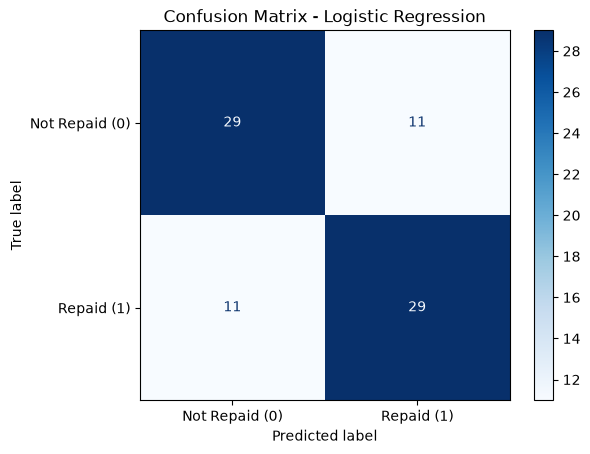

Classification Report:
                precision    recall  f1-score   support

Not Repaid (0)       0.72      0.72      0.72        40
    Repaid (1)       0.72      0.72      0.72        40

      accuracy                           0.72        80
     macro avg       0.72      0.72      0.72        80
  weighted avg       0.72      0.72      0.72        80



In [14]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Create and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Repaid (0)", "Repaid (1)"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# Display the classification report
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Repaid (0)", "Repaid (1)"],
    zero_division=0
))
# Hint: `confusion_matrix`, `ConfusionMatrixDisplay`, `classification_report`.

### B5. Which mistake is worse? 

In this loan problem, **1 = repaid** is the "positive" class.

Explain in your own words what a **false positive** and a **false negative** mean here. Which one costs the company more, and which metric (precision or recall for the "Repaid" class) would you watch most closely?

A false positive means the model predicts that an applicant will repay the loan when they actually will not. A false negative means the model predicts that an applicant will not repay the loan when they actually will. I would pay close attention to false positives because they can cause the lender to lose money by approving loans to applicants who default. However, false negatives also matter because they can lead to rejecting applicants who would have repaid their loans.

*(double-click here and type your answer)*

### B6. Compare with a Decision Tree 

Train a `DecisionTreeClassifier(max_depth=3, random_state=42)` on the same training data and print its **test accuracy**. Then print the two accuracies side by side. Which model did better?

In [15]:
# Train the Decision Tree
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

# Predict using both models
log_pred = model.predict(X_test)
tree_pred = tree_model.predict(X_test)

# Calculate test accuracy
log_accuracy = accuracy_score(y_test, log_pred)
tree_accuracy = accuracy_score(y_test, tree_pred)

# Print both accuracies
print("Logistic Regression accuracy:", log_accuracy)
print("Decision Tree accuracy:", tree_accuracy)

if tree_accuracy > log_accuracy:
    print("Decision Tree performed better.")
elif log_accuracy > tree_accuracy:
    print("Logistic Regression performed better.")
else:
    print("Both models had the same accuracy.")
# Hint: Trees do not need scaling. Use `.fit()`, `.predict()` and `accuracy_score`.

Logistic Regression accuracy: 0.725
Decision Tree accuracy: 0.6125
Logistic Regression performed better.


### B7. Challenge: change the decision threshold 

By default the model approves anyone with a repayment probability **above 0.5**. The company wants to be **stricter** and only approve applicants with a probability **above 0.7**.

Use `predict_proba` to apply this new threshold on the test set, then print the **precision and recall** for the "Repaid" class **before and after**. What changed?

In [16]:
# Default predictions (threshold = 0.5)
default_pred = model.predict(X_test)

# Get repayment probabilities
probs = model.predict_proba(X_test)[:, 1]

# Apply the stricter threshold
new_pred = (probs > 0.7).astype(int)

# Precision and recall before the change
print("Before threshold change:")
print("Precision:", precision_score(y_test, default_pred, zero_division=0))
print("Recall:", recall_score(y_test, default_pred, zero_division=0))

# Precision and recall after the change
print("\nAfter threshold change:")
print("Precision:", precision_score(y_test, new_pred, zero_division=0))
print("Recall:", recall_score(y_test, new_pred, zero_division=0))
# Hint: `probs = log_model.predict_proba(X_test)[:, 1]`, then `new_pred = (probs > 0.7).astype(int)`.

Before threshold change:
Precision: 0.725
Recall: 0.725

After threshold change:
Precision: 0.8181818181818182
Recall: 0.45


---
# PART C: Reflection
Answer in your own words, in 2 to 4 sentences each.

### C1. Linear vs Logistic

What is the main difference between Linear Regression and Logistic Regression? Give one real-life example for each.

Linear regression is used to predict a numerical value based on the relationship between variables. For example, it can predict a student's exam score based on the number of hours they study.

Logistic regression is used to predict the probability of an outcome and classify it into a category. For example, it can predict whether a student is likely to pass or fail an exam based on their study hours.

*(double-click here and type your answer)*

### C2. Why split the data? 

Why do we split our data into a training set and a test set? What could go wrong if we tested the model on the same data it learned from?

We split data into training and test sets so the model can learn from the training data and then be evaluated on new, unseen data to see how well it performs. If we test the model using the same data it learned from, it may simply memorize the data and give misleadingly good results instead of showing how well it can make predictions on new data.

*(double-click here and type your answer)*

### C3. Why scale for logistic regression? 

In Part B we used `StandardScaler` before logistic regression. Why is scaling useful when features such as `monthly_income_k` (about 120) and `previous_defaults` (0 to 3) have very different ranges?

Scaling is useful because it puts features with different ranhges on similar scale, so monthly_income_k does not dominate previous_defaults just because its values are larger. This helps logistic regression learn more efficiently and can improve model convergence.

*(double-click here and type your answer)*

---
## Before you submit: checklist
- [ ] I ran **Restart & Run All** and there are no errors
- [ ] Every `# YOUR CODE HERE` cell has my own code
- [ ] I answered all the written questions in my own words
- [ ] My plots have titles and axis labels
- [ ] I saved the file as `Week3_Assignment_YourName.ipynb`

**Good luck!**